## Анализ и прогнозирование временных рядов методами искусственного интеллекта

### **Практическая работа 3. Поиск аномалий во временных рядах.**


#### **3.1 Поиск диссонансов с помощью алгоритма HotSAX**

##### 3.1.1 Загрузка и подготовка данных

В данной будет использоваться временной ряд, состоящий из показаний акселерометра. 
Анализируемый временной ряд, описывает две активности человека - бег и шаг.


In [1]:
!pip install scipy
!pip install scikit-learn


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [2]:
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from time import time
import pandas as pd

In [3]:
#fixme: Путь
dataset_dir_path = Path('datasets')
data_path = dataset_dir_path/'walk_run.txt'
walk_run = np.loadtxt(data_path)[3000:4000]
data = walk_run
size_sub = 50

В середине временного ряда происходит смена активности (бег заменяет шаг). Нетипичным поведением, которое мы могли бы назвать диссонансами в данном ряде выступает небольшой участок между активностями, когда человек плавно увеличивает скорость шага до бега. В ходе данной работе наша задача выделить с помощью различных алгоритмов границы нашего диссонанса.

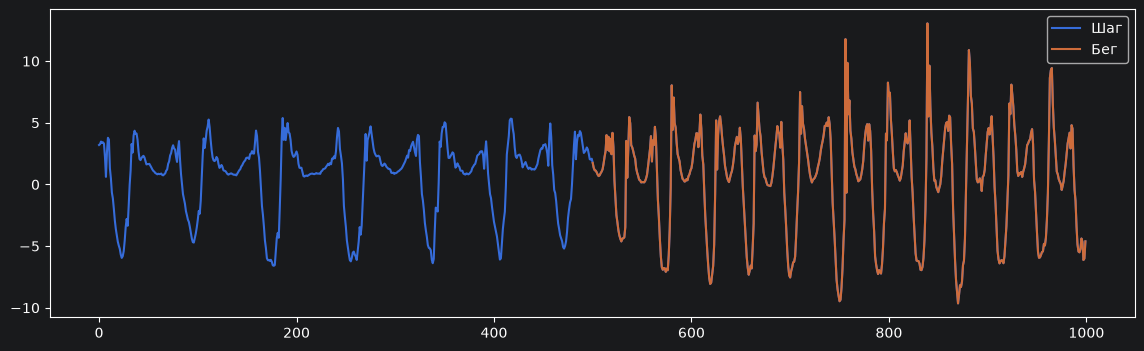

In [4]:
fig, ax =  plt.subplots(figsize=(14,4),ncols=1,nrows=1)
plt.plot(data[:],label='Шаг')
plt.plot(np.arange(data.shape[0]//2,data.shape[0]),data[data.shape[0]//2:],label='Бег')
plt.legend()

In [5]:
result={}
times={}

##### 3.1.2 Реализация полного перебора

Приводится пример кода для нахождения топ 5 диссонансов с помощью реализации полного беребора.
Вам необходимо добавить код для сбора времени обработки данных.

In [6]:
from modules.saxpy.discord import find_discords_brute_force
start = time()
discords_brute_force = np.stack(find_discords_brute_force(data[:], size_sub, 5))
end = time()
times['brute_force'] = end - start
result['brute_force'] = discords_brute_force
print('Полный перебор, секунды:', round(times['brute_force'], 3))
print(discords_brute_force)


Полный перебор, секунды: 26.066
[[477.           5.88100934]
 [412.           5.32704317]
 [195.           3.39426635]
 [577.           3.35554403]
 [278.           3.10959389]]


##### 3.1.3 HotSAX

Используя [реализацию](https://github.com/seninp/saxpy/blob/master/saxpy/hotsax.py) найдите топ 5 диссонансов ряда.
Произведите замер времени работы.

In [7]:
from modules.saxpy.hotsax import find_discords_hotsax

start = time()
discords_hotsax = np.stack(find_discords_hotsax(data, win_size=size_sub, num_discords=5))
end = time()
times['hotsax'] = end - start
result['hotsax'] = discords_hotsax
print('HotSAX, секунды:', round(times['hotsax'], 3))
print(discords_hotsax)


HotSAX, секунды: 0.407
[[477.           5.88100934]
 [412.           5.32704317]
 [195.           3.39426635]
 [577.           3.35554403]
 [278.           3.10959389]]


##### 3.1.4 Визаулизация

Вам необходимо реализовать код позволяющий:
1. Вывести на одном графике ряд и его диссонансы
2. Столбчатую диаграмму времени работы обоих алгоритмов
   
Постройте графики для обоих алгоритмов и сравните полученные результаты.

Пример графика:

![first_graf](pics/fig_ex_1.png)

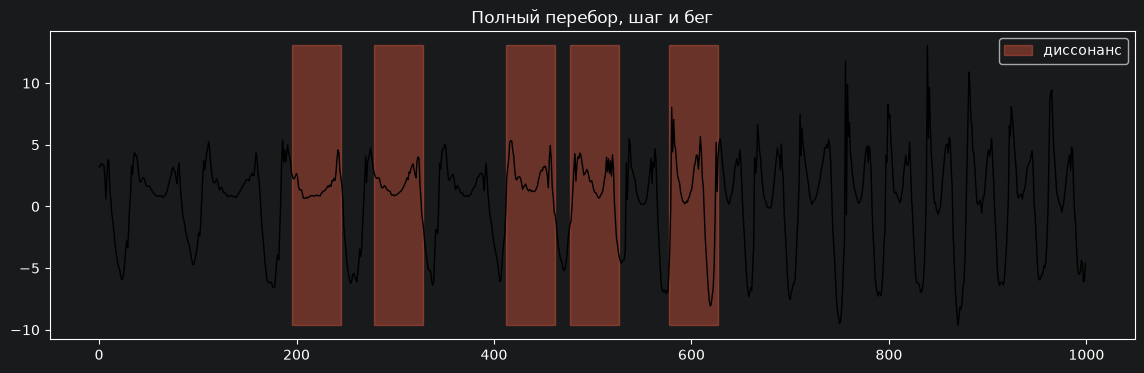

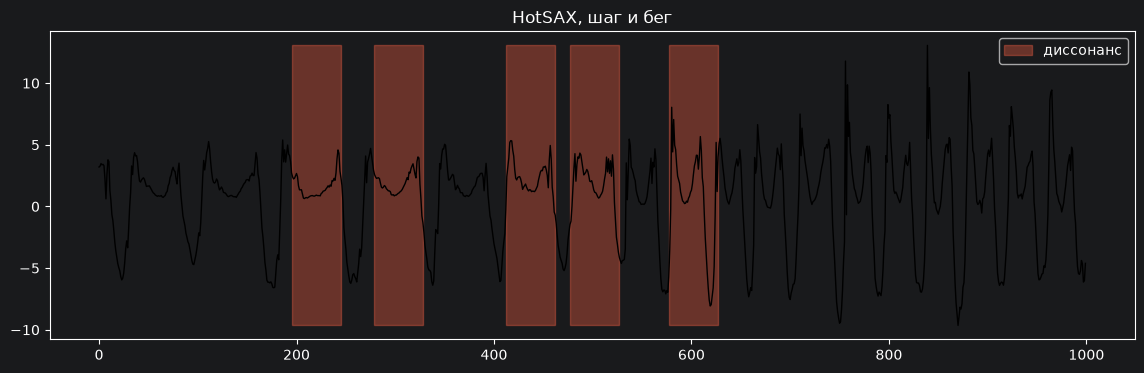

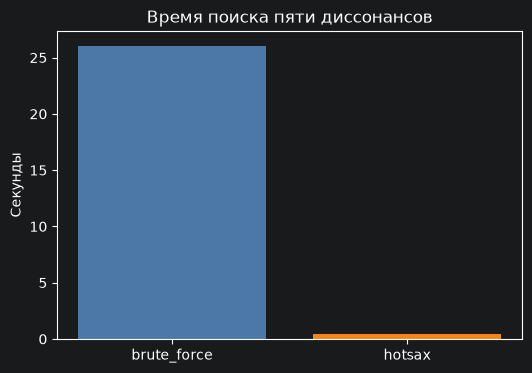

Индексы совпали: True


In [8]:
def plot_discord_series(series, discords, win_size, title):
    figure, axis = plt.subplots(figsize=(14, 4))
    axis.plot(series, color='black', linewidth=1)
    lower = np.min(series)
    height = np.max(series) - lower
    labeled = False
    for item in discords:
        start_index = int(item[0])
        axis.add_patch(Rectangle(
            (start_index, lower),
            win_size,
            height,
            color='tomato',
            alpha=0.35,
            label='диссонанс' if not labeled else None,
        ))
        labeled = True
    axis.set_title(title)
    axis.legend()
    plt.show()

plot_discord_series(data, result['brute_force'], size_sub, 'Полный перебор, шаг и бег')
plot_discord_series(data, result['hotsax'], size_sub, 'HotSAX, шаг и бег')

plt.figure(figsize=(6, 4))
plt.bar(list(times.keys()), list(times.values()), color=['#4C78A8', '#F58518'])
plt.ylabel('Секунды')
plt.title('Время поиска пяти диссонансов')
plt.show()

print('Индексы совпали:', np.allclose(result['brute_force'][:, 0], result['hotsax'][:, 0]))


In [9]:
from matplotlib.patches import Rectangle

##### 3.1.5 Такси NY

Произведите поиск диссонансов с помощью обоих алгоритмов на наборе данных, содержащим информацию о среднем числе пассажиров в NY. Отобразите найденные диссонансы обоими алгоритмами. 

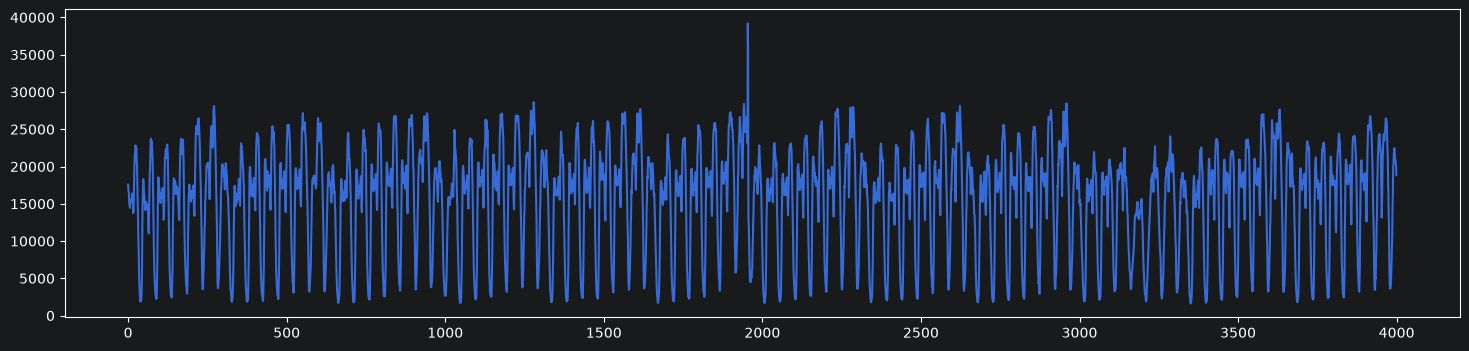

In [10]:
nyc_taxi = pd.read_csv(dataset_dir_path/'nyc_taxi.csv',index_col=0).values[4000:8000,0].astype(np.float64)
fig = plt.figure(figsize=(18, 4))
plt.plot(nyc_taxi)

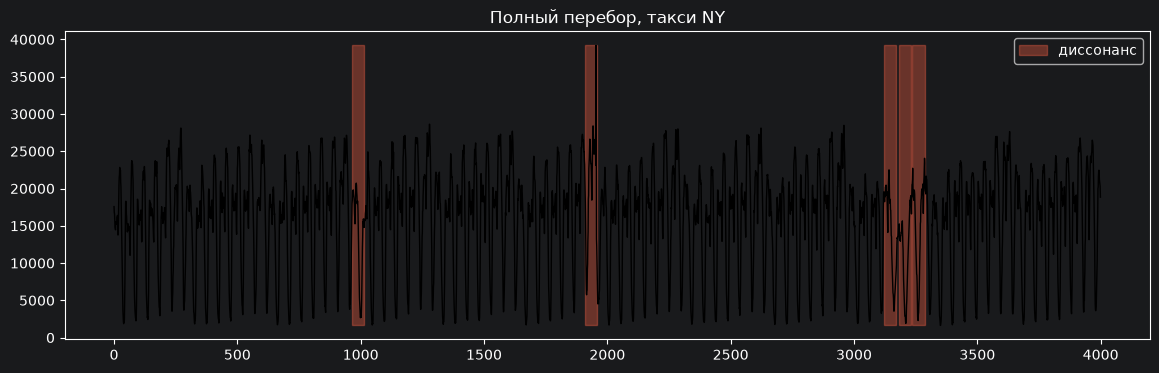

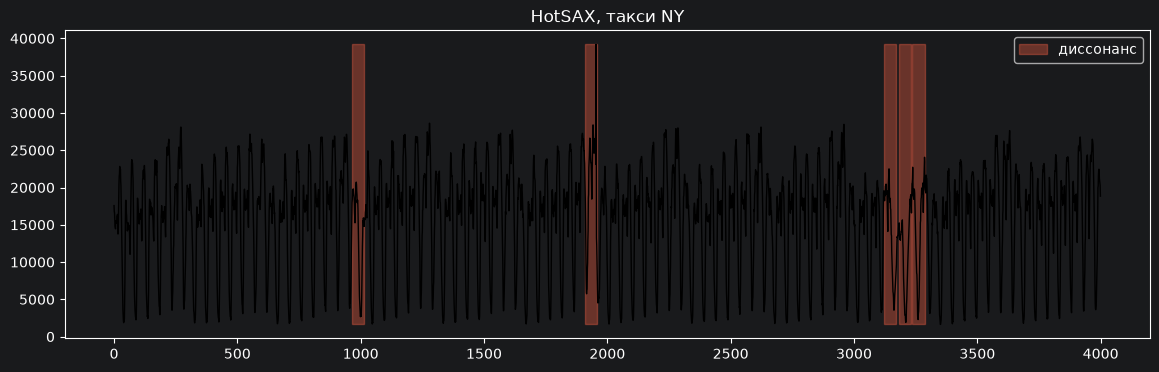

Полный перебор, секунды: 1195.249 [(1910, np.float64(3.5268153024066273)), (3120, np.float64(3.4023316427088974)), (3183, np.float64(2.6420409697541243)), (3237, np.float64(2.22922774558654)), (963, np.float64(1.6115276543785826))]
HotSAX, секунды: 1.6 [(1910, np.float64(3.5268153024066273)), (3120, np.float64(3.402331642708897)), (3183, np.float64(2.642040969754124)), (3237, np.float64(2.22922774558654)), (963, np.float64(1.6115276543785826))]


In [11]:
nyc_win = 50
start = time()
nyc_brute = find_discords_brute_force(nyc_taxi, nyc_win, 5)
times['nyc_brute_force'] = time() - start

start = time()
nyc_hotsax = find_discords_hotsax(nyc_taxi, win_size=nyc_win, num_discords=5)
times['nyc_hotsax'] = time() - start

plot_discord_series(nyc_taxi, nyc_brute, nyc_win, 'Полный перебор, такси NY')
plot_discord_series(nyc_taxi, nyc_hotsax, nyc_win, 'HotSAX, такси NY')
print('Полный перебор, секунды:', round(times['nyc_brute_force'], 3), nyc_brute)
print('HotSAX, секунды:', round(times['nyc_hotsax'], 3), nyc_hotsax)


#### **3.2 Поиск диссонансов с помощью алгоритма DRAG**

In [12]:
!pip install stumpy==1.11.1


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [13]:
import stumpy
from stumpy import core, config
from stumpy.scrump import _prescrump


/Users/anatolijkrylov/Documents/2026---TimeSeriesCourse/practice/03 Discords/.venv/lib/python3.14/site-packages/stumpy/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


Как мы помним из лекций:

**Диапазонный диссонанс** – подпоследовательность ряда, расстояние от которой до ее ближайшего соседа не ниже заданного порога. 

Основными параметрами при поисках диссонансов являются:
- $m$ - длина диссонанса
- $r$ - пороговое значение расстояния подпоследовательности ряда, до его ближайшего соседа


In [14]:
from modules.drag import find_candidates, DRAG


Для поиска диссонансов в данной части практической работы мы воспользуемся алгоритмом **DRAG (Discord Range Aware Gathering)**.
Для начала воспользуемся данным алгоритмом, чтобы найти диссонансы в наборе данных содержащем активность человека.

In [15]:
data = walk_run

Длину искомого диссонанса, как и для предыдущих алгоритмов, мы установим равно 50 точек.
Пороговое значение мы установим равным большим, чтобы узнать, как алгоритм отреагирует на большие значения данного параметра.

In [16]:
m = 50 
r = 10
idxs, _, _ = DRAG(data,m,r)
print(f'Колличество найденных диссонансов: {len(idxs)}')

Колличество найденных диссонансов: 0


Как вы можете видеть мы установили слишком большое пороговое значение, алгоритму не удалось выделить ни одного диссонанса. Попробуем уменьшить пороговое значение до 1, чтобы улучшить результат. 

In [17]:
m = 50 
r = 1
idxs, _, _ = DRAG(data, m, r)
print(f'Колличество найденных диссонансов: {len(idxs)}')

Колличество найденных диссонансов: 50


При такой комбинации параметров, улучшить ситуацию не получилось. Алгоритм выделил слишком большое количество диссонансов, часть которых является ложными диссонансами и не будут информативными для нас.

Произведите подобные эксперименты с набором данных такси NY. Постройте графики демонстрирующие найденные диссонансы. Пример Графика:
![second-graph](pics/fig_ex_2.png)

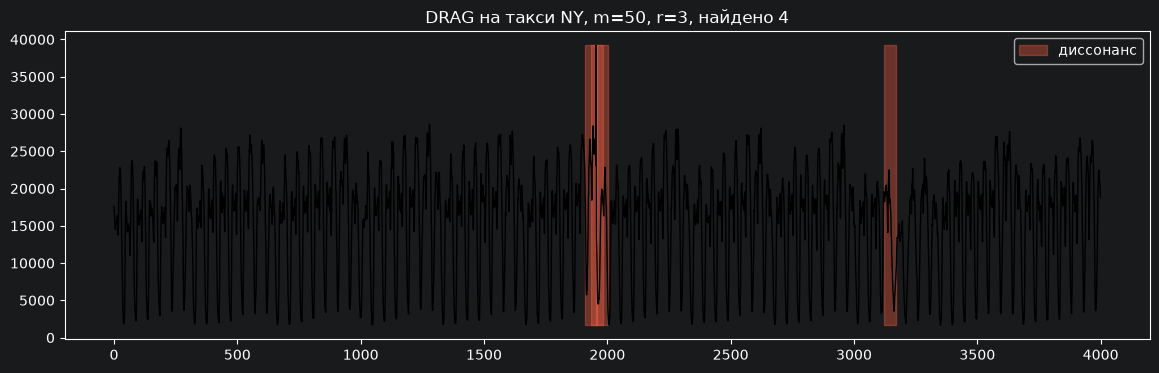

[(np.int64(1910), np.float64(3.527)), (np.int64(1952), np.float64(3.489)), (np.int64(3120), np.float64(3.402)), (np.int64(1934), np.float64(3.093))]


In [18]:
m = 50
r = 3
nyc_idxs, nyc_dist, nyc_nn = DRAG(nyc_taxi, m, r)
plot_discord_series(
    nyc_taxi,
    list(zip(nyc_idxs, nyc_dist)),
    m,
    f'DRAG на такси NY, m={m}, r={r}, найдено {len(nyc_idxs)}',
)
print(list(zip(nyc_idxs, np.round(nyc_dist, 3))))


Чтобы разобраться, почему так происходит и как работает данный алгоритм, ниже мы реализуем все этапы алгоритма DRAG.

Как мы помним из лекций алгоритм DRAG содержит два этапа:

1. Отбор - За одно сканирование ряда сформировать множество кандидатов в диссонансы.
2. Очистка - За одно сканирование ряда отбросить кандидатов, которые являются ложными диссонансами.

##### 3.2.1 Отбор кандидатов

Первым этапом обработки данных является отбор множества потенциальных кандидатов. Мы выбираем из всего множества подпоследовательностей ряда такие, для которых расстояние до правых ближайших соседей больше параметра $r$.

In [19]:
#выбирем более реальное значение для порога
r = 3

In [20]:
T, M_T, Σ_T = core.preprocess(data, m)
#формируем массив длинной равной длине  исходного ряда - m + 1, 
#элемент массива является истинным, 
#в том случае если подпоследовательность является потенциальным кандидатом
is_cands = find_candidates(T, m, M_T, Σ_T, r, init_cands=None, right=True)
#находим индексы потенциальных кандидатов
cand_index = np.flatnonzero(is_cands)

In [21]:
print(f'{len(cand_index)} {len(cand_index)/len(data)*100} %')

113 11.3 %


Во время отбора кандидатов нам удалось выделить около 113 подпоследовательностей(около 11.3%), которые мы бы могли назвать потенциальными диссонансами.
Это большой процент, который не может нас устраивать как конечный результат.
Если посмотреть на рисунок ниже, мы увидим, что большая часть потенциальных диссонансов расположена в районе смены активности. 
К сожалению пресутсвуют и ложные диссонансы, которые случайным образом попали в данный список.

Сформируйте график найденных диссонансов

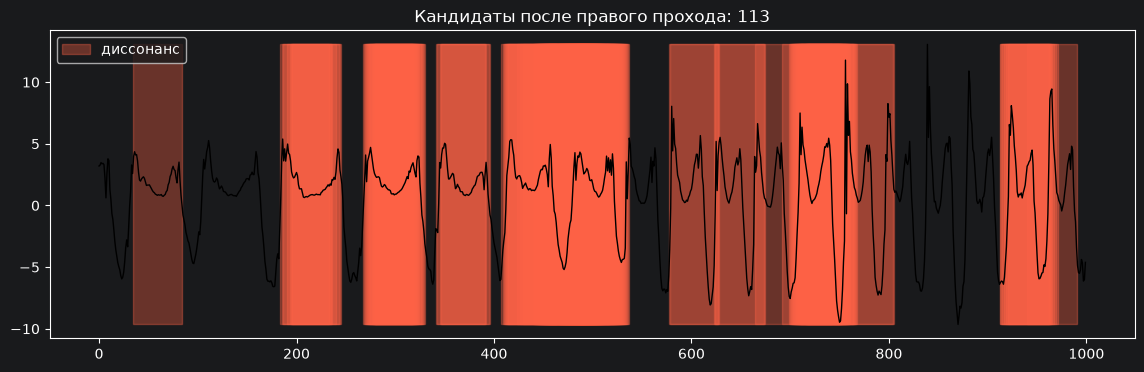

In [22]:
plot_discord_series(
    data,
    [(idx, 0) for idx in cand_index],
    m,
    f'Кандидаты после правого прохода: {len(cand_index)}',
)


##### 3.2.2 Очистка кандидатов
Как уже упоминалось выше, 11.3% слишком большой процент диссонансов.
Для уменьшения числа потенциальных кандидатов произведем очистку от ложных диссонансов, путем сравнения расстояния до левых ближайших соседей потенциальных диссонансов с порогом $r$.


In [23]:
is_cands = find_candidates(T, m, M_T, Σ_T, r, init_cands=is_cands, right=False)
cands = np.flatnonzero(is_cands)

In [24]:
len(cands)/len(data)*100

2.9000000000000004

Сформируйте график найденных диссонансов

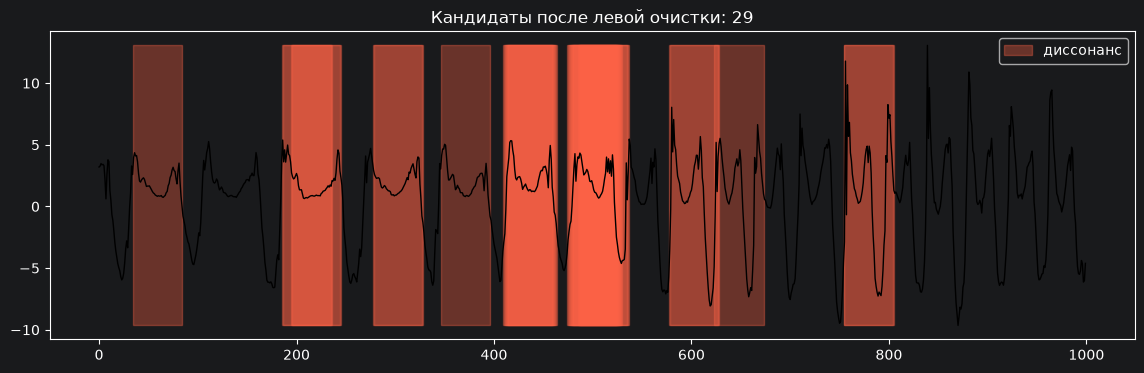

In [25]:
plot_discord_series(
    data,
    [(idx, 0) for idx in cands],
    m,
    f'Кандидаты после левой очистки: {len(cands)}',
)


Нам удалось сократить число диссонансов до 2.9%. Если проанализировать рисунок, то можно заметить, что большая их часть является тривиальными повторениями подпоследовательности в области смены активности. На следующем шаге избавимся от них.

In [26]:
from modules.drag import refine_candidates
discords_idx, discords_dist, discords_nn_idx = refine_candidates(T, m, M_T, Σ_T, is_cands)
len(discords_idx)/len(data)*100

0.8999999999999999

Сформируйте график найденных диссонансов

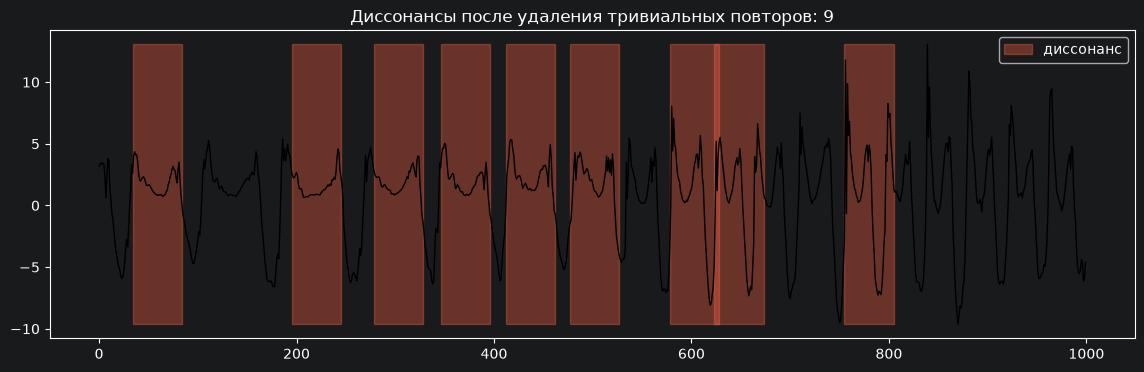

In [27]:
plot_discord_series(
    data,
    list(zip(discords_idx, discords_dist)),
    m,
    f'Диссонансы после удаления тривиальных повторов: {len(discords_idx)}',
)


##### 3.2.3 Подбор параметров

Реализуйте перебор параметров $m$ и $r$. Подберете параметры таким образом, чтобы алгоритм обнаружил только те диссонансы, которые связаны со сменой активности. Сделайте вывод о том, как эти параметры влияют на качество работы модели.
Подберите оптимальные параметры алгоритма для набора данных такси NY. 
Визуализируйте результаты для разных комбинаций. Сделайте выводы.


Шаг и бег. Смена активности около отсчёта 500.
m= 30 r=2  всего= 14  у смены активности=4  первые=[201, 493, 537, 665]
m= 30 r=3  всего=  1  у смены активности=0  первые=[201]
m= 30 r=5  всего=  0  у смены активности=0  первые=[]
m= 30 r=8  всего=  0  у смены активности=0  первые=[]
m= 50 r=2  всего= 24  у смены активности=8  первые=[477, 412, 195, 578]
m= 50 r=3  всего=  9  у смены активности=3  первые=[477, 412, 195, 578]
m= 50 r=5  всего=  2  у смены активности=2  первые=[477, 412]
m= 50 r=8  всего=  0  у смены активности=0  первые=[]
m= 80 r=2  всего= 34  у смены активности=8  первые=[469, 490, 448, 575]
m= 80 r=3  всего= 22  у смены активности=8  первые=[469, 490, 448, 575]
m= 80 r=5  всего=  2  у смены активности=2  первые=[469, 490]
m= 80 r=8  всего=  0  у смены активности=0  первые=[]


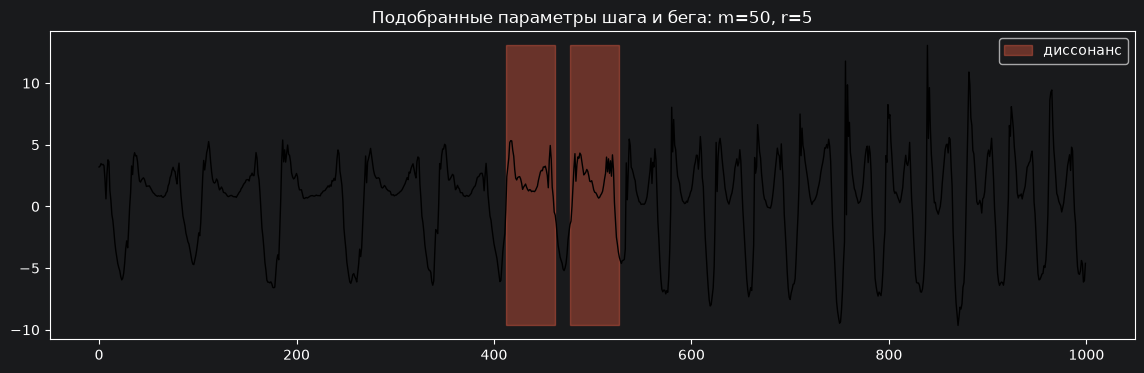

Такси NY
m= 50 r=2  всего=  8  первые=[1910, 1952, 3120, 1934]
m= 50 r=3  всего=  4  первые=[1910, 1952, 3120, 1934]
m= 50 r=5  всего=  0  первые=[]
m=100 r=2  всего= 16  первые=[3103, 3137, 3075, 3194]
m=100 r=3  всего=  9  первые=[3103, 3137, 3075, 3194]
m=100 r=5  всего=  3  первые=[3103, 3137, 3075]


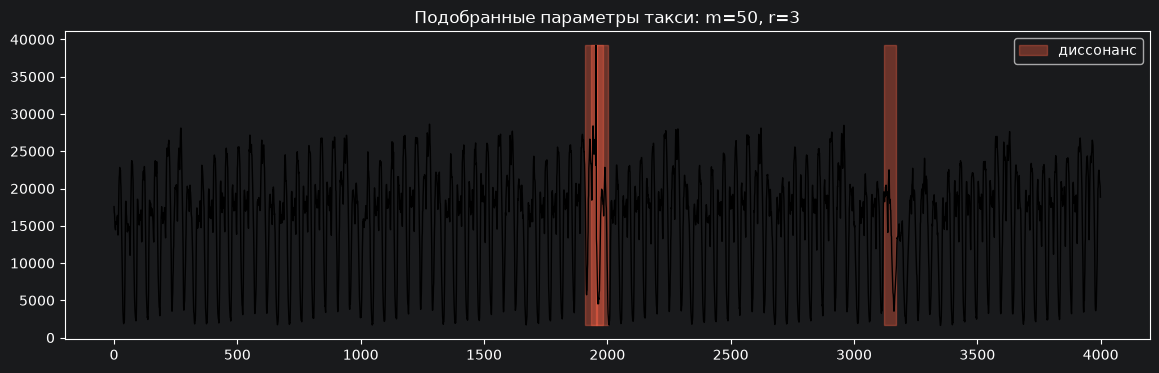

In [28]:
print('Шаг и бег. Смена активности около отсчёта 500.')
for window in (30, 50, 80):
    for threshold in (2, 3, 5, 8):
        found_idx, found_dist, _ = DRAG(data, window, threshold)
        near_change = sum(400 <= int(idx) <= 600 for idx in found_idx)
        print(
            f'm={window:3d} r={threshold}  всего={len(found_idx):3d}  '
            f'у смены активности={near_change}  первые={list(map(int, found_idx[:4]))}'
        )

chosen_m, chosen_r = 50, 5
walk_drag_idx, walk_drag_dist, _ = DRAG(data, chosen_m, chosen_r)
plot_discord_series(
    data,
    list(zip(walk_drag_idx, walk_drag_dist)),
    chosen_m,
    f'Подобранные параметры шага и бега: m={chosen_m}, r={chosen_r}',
)

print('Такси NY')
for window in (50, 100):
    for threshold in (2, 3, 5):
        found_idx, found_dist, _ = DRAG(nyc_taxi, window, threshold)
        print(f'm={window:3d} r={threshold}  всего={len(found_idx):3d}  первые={list(map(int, found_idx[:4]))}')

taxi_m, taxi_r = 50, 3
taxi_drag_idx, taxi_drag_dist, _ = DRAG(nyc_taxi, taxi_m, taxi_r)
plot_discord_series(
    nyc_taxi,
    list(zip(taxi_drag_idx, taxi_drag_dist)),
    taxi_m,
    f'Подобранные параметры такси: m={taxi_m}, r={taxi_r}',
)


#### **3.3 Поиск диссонансов с помощью алгоритма Merlin**

Как мы уже выяснили подбирать параметры для DRAG простым перебором не очень удобно. Для оптимизации данного процесса в статье [1] был предложен алгоритм Merlin для оптимального поиска подходящего порогового значения.

Условно мы можем разделить поиск диссонансов на три шага:

1. Поиск диссонансов минимальной длинны $minL$. На данном шаге $r = 2\sqrt{minL}$.
2. Поиск диссонансов следующих четырех длин. На данном шаге $r = 0.99 \cdot nndist_{m-1}$. Где $nndist_{m-1}$ - расстояние до ближайшего соседа предыдущего найденного диссонанса.
3. Поиск диссонансов всех 
оставшихся дли. $r = \mu - 2 \sigma$. Средние значение и стандартное отклонение вычисляются из расстояний 5 предыдущих диссонансов. н

[1] Nakamura T., Imamura M., Mercer R., Keogh E.J. MERLIN: parameter-free discovery of arbitrary length anomalies in massive time series archives. 20th IEEE Int. Conf. on Data Mining, ICDM 2020, Sorrento, Italy, November 17-20, 2020. pp. 1190-1195. IEEE (2020). https://doi.org/10.1109/ICDM50108.2020.00147

##### 3.3.1 Поиск диссонансов минимальной длинны

Вспомнил последовательность действий первого шага алгоритма:
![merlin-part-first](pics/first_part.png)

В данной работе мы внесем небольшое изменение, мы будем считать, что подпоследовательность может быть диссонансом только в том случае, если больше 75% точек, не входят в состав других диссонансов. 

In [29]:
T = walk_run
m = 50
# сформируем массив метод для потенциальных кандидатов в диссонансы.
# после каждого найденного диссонанса, 
# мы будем исключать окружающие его подпоследовательности из числа потенциальных кандидатов,
# путем замены значений их меток на false
excl_zone = int(np.ceil(m / 4))
include = np.ones(len(T)-m+1, dtype=bool)
# Количество диссонансов, которые мы будем искать
topK = 10


In [30]:
dis_idx = -np.ones((topK))
dis_nnDist = -np.ones((topK))
dis_nn_idx = np.full((topK),-np.inf)
#первое прближение r
r = 2*np.sqrt(m)
minL = m
maxL = int(m+np.ceil(m*0.1))
#количество найденных диссонасов
cound_find_dis = 0

while dis_nnDist[cound_find_dis-1]<0 and cound_find_dis<topK:
    result = DRAG(data=T,m=minL,r=r, include =include)
    for diss, nnDist, nn in zip(*result):
        dis_idx[cound_find_dis] = diss
        dis_nnDist[cound_find_dis] = nnDist
        dis_nn_idx[cound_find_dis] = nn
        #исключаем окружающие найденный диссонас 
        #подпоследовательности и числа потенциальных диссонасов
        core.apply_exclusion_zone(include, diss, excl_zone, False)
        cound_find_dis+=1
        if cound_find_dis>=topK:
            break
    r*=0.5

In [31]:
maxL

55

In [32]:
print('Количество найденных на первом этапе диссонансов:', cound_find_dis)

Количество найденных на первом этапе диссонансов: 2


На первом шаге нам удалось выделить 2 диссонанса из 10 требуемых. 
Реализуйте, оставшиеся шаги алгоритма, чтобы найти оставшиеся диссонансы. 

![merlin-part-first](pics/second_part.png)


In [33]:
def _store_discords(result, zone):
    """Записать диссонансы DRAG и вернуть их расстояния до соседа."""
    accepted = []
    global cound_find_dis
    for diss, nn_dist, nn in zip(*result):
        if cound_find_dis >= topK:
            break
        dis_idx[cound_find_dis] = diss
        dis_nnDist[cound_find_dis] = nn_dist
        dis_nn_idx[cound_find_dis] = nn
        core.apply_exclusion_zone(include, int(diss), zone, False)
        cound_find_dis += 1
        accepted.append(float(nn_dist))
    return accepted

# Шаг 2. Длины minL+1 ... minL+4.
# Порог начинается с 0.99 от расстояния предыдущей длины.
# Пустой проход умножает порог на 0.99, как на схеме второго шага.
for length in range(minL + 1, minL + 5):
    if cound_find_dis >= topK:
        break
    zone = int(np.ceil(length / 4))
    nn_dist_length = -np.inf
    r = 0.99 * float(dis_nnDist[cound_find_dis - 1])
    while nn_dist_length < 0 and cound_find_dis < topK and r > 1e-4:
        accepted = _store_discords(DRAG(data=T, m=length, r=float(r), include=include), zone)
        if accepted:
            nn_dist_length = min(accepted)
        r *= 0.99

# Шаг 3. Оставшиеся длины до maxL.
# Первый вызов: r = среднее пяти прошлых расстояний минус два стандартных отклонения.
# Пока длина ничего не дала, вычитаем одно стандартное отклонение и вызываем DRAG снова.
for length in range(minL + 5, maxL + 1):
    if cound_find_dis >= topK:
        break
    previous = dis_nnDist[max(0, cound_find_dis - 5):cound_find_dis]
    previous = previous[previous >= 0]
    mu = float(np.mean(previous))
    sigma = float(np.std(previous))
    r = mu - 2 * sigma
    zone = int(np.ceil(length / 4))
    accepted = _store_discords(DRAG(data=T, m=length, r=float(r), include=include), zone)
    nn_dist_length = min(accepted) if accepted else -np.inf
    while nn_dist_length < 0 and cound_find_dis < topK and sigma > 0:
        r -= sigma
        accepted = _store_discords(DRAG(data=T, m=length, r=float(r), include=include), zone)
        if accepted:
            nn_dist_length = min(accepted)

print('Найдено диссонансов:', cound_find_dis)
print(list(zip(dis_idx[:cound_find_dis].astype(int), np.round(dis_nnDist[:cound_find_dis], 3))))


Найдено диссонансов: 9
[(np.int64(477), np.float64(5.881)), (np.int64(412), np.float64(5.327)), (np.int64(195), np.float64(3.439)), (np.int64(575), np.float64(3.323)), (np.int64(31), np.float64(3.259)), (np.int64(343), np.float64(3.259)), (np.int64(755), np.float64(3.241)), (np.int64(623), np.float64(3.238)), (np.int64(109), np.float64(3.024))]


Найдите диссонансы набора такси NY. Визуализируйте найденные диссонансы для обоих наборов данных, сравните с результатами остальных методов. 


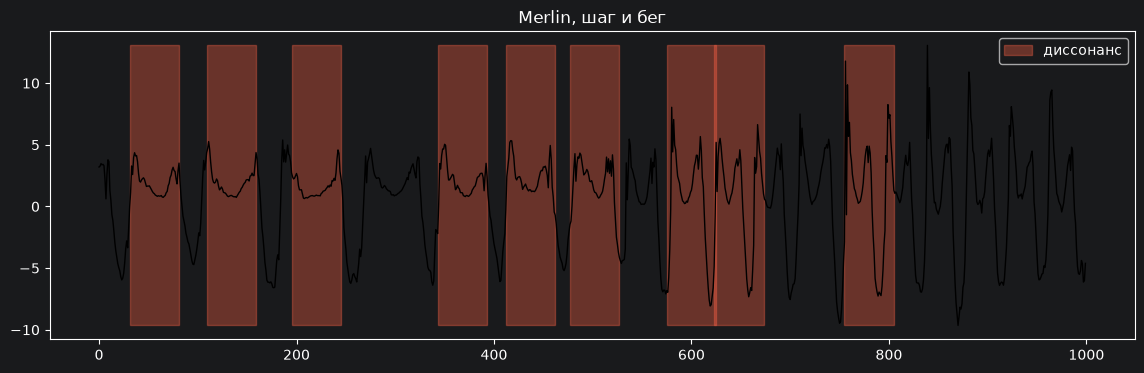

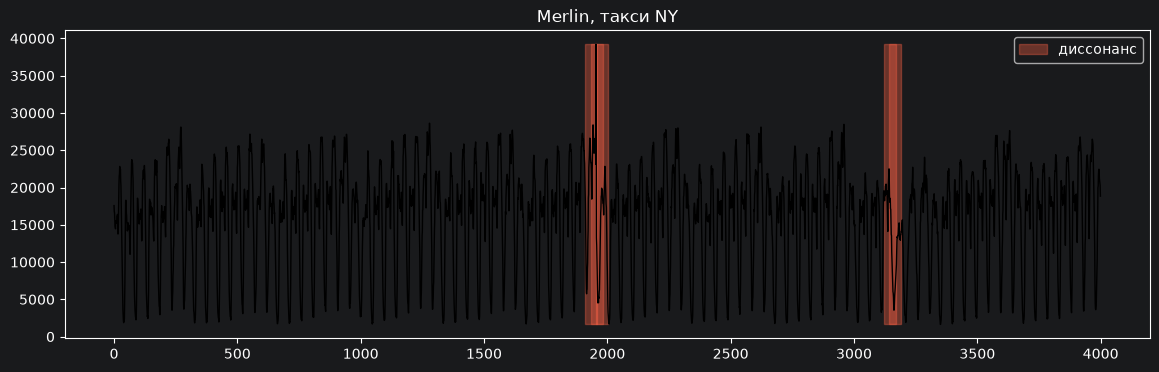

Merlin, такси: [(np.int64(1910), np.float64(3.527)), (np.int64(1952), np.float64(3.489)), (np.int64(3120), np.float64(3.402)), (np.int64(1934), np.float64(3.093)), (np.int64(3142), np.float64(2.771))]
HotSAX, такси: [1910, 3120, 3183, 3237, 963]
Полный перебор, такси: [1910, 3120, 3183, 3237, 963]
DRAG m=50 r=3, такси: [1910, 1952, 3120, 1934]


In [34]:
plot_discord_series(
    walk_run,
    list(zip(dis_idx[:cound_find_dis], dis_nnDist[:cound_find_dis])),
    m,
    'Merlin, шаг и бег',
)

def merlin_discords(series, min_length, top_k=5):
    zone0 = int(np.ceil(min_length / 4))
    mask = np.ones(len(series) - min_length + 1, dtype=bool)
    positions = -np.ones(top_k)
    distances = -np.ones(top_k)
    found = 0
    threshold = 2 * np.sqrt(min_length)
    max_length = int(min_length + np.ceil(min_length * 0.1))

    def store(result, zone):
        nonlocal found
        accepted = []
        for diss, nn_dist, nn in zip(*result):
            if found >= top_k:
                break
            positions[found] = diss
            distances[found] = nn_dist
            core.apply_exclusion_zone(mask, int(diss), zone, False)
            found += 1
            accepted.append(float(nn_dist))
        return accepted

    while distances[found - 1] < 0 and found < top_k and threshold > 1e-4:
        store(DRAG(series, min_length, float(threshold), mask), zone0)
        threshold *= 0.5

    for length in range(min_length + 1, min_length + 5):
        if found >= top_k:
            break
        zone = int(np.ceil(length / 4))
        nn_dist_length = -np.inf
        threshold = 0.99 * float(distances[found - 1])
        while nn_dist_length < 0 and found < top_k and threshold > 1e-4:
            accepted = store(DRAG(series, length, float(threshold), mask), zone)
            if accepted:
                nn_dist_length = min(accepted)
            threshold *= 0.99

    for length in range(min_length + 5, max_length + 1):
        if found >= top_k:
            break
        previous = distances[max(0, found - 5):found]
        previous = previous[previous >= 0]
        mu = float(np.mean(previous))
        sigma = float(np.std(previous))
        threshold = mu - 2 * sigma
        zone = int(np.ceil(length / 4))
        accepted = store(DRAG(series, length, float(threshold), mask), zone)
        nn_dist_length = min(accepted) if accepted else -np.inf
        while nn_dist_length < 0 and found < top_k and sigma > 0:
            threshold -= sigma
            accepted = store(DRAG(series, length, float(threshold), mask), zone)
            if accepted:
                nn_dist_length = min(accepted)
    return positions[:found], distances[:found]

nyc_merlin_idx, nyc_merlin_dist = merlin_discords(nyc_taxi, min_length=50, top_k=5)
plot_discord_series(
    nyc_taxi,
    list(zip(nyc_merlin_idx, nyc_merlin_dist)),
    50,
    'Merlin, такси NY',
)
print('Merlin, такси:', list(zip(nyc_merlin_idx.astype(int), np.round(nyc_merlin_dist, 3))))
print('HotSAX, такси:', [int(item[0]) for item in nyc_hotsax])
print('Полный перебор, такси:', [int(item[0]) for item in nyc_brute])
print('DRAG m=50 r=3, такси:', list(map(int, taxi_drag_idx)))
